<a href="https://colab.research.google.com/github/Dishitha09/csda-al/blob/main/notebooks/CSDA_AL_ISIC2019_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CSDA-AL: Class-Sensitive Deep Active Learning on ISIC 2019
### Google Colab GPU Execution Pipeline

This notebook runs the complete **CSDA-AL** active learning pipeline on Google Colab with hardware acceleration (GPU T4/V100/A100).

**Key Highlights:**
- Clone repository directly from GitHub: `https://github.com/Dishitha09/csda-al.git`
- High-speed GPU feature extraction on ISIC 2019
- Complete Active Learning Benchmarking (B0, B1, M1–M7, C1–C4 Across 3 Seeds)
- Instant visualization of all 12 publication figures & comparison tables

## 1. Verify GPU Hardware Acceleration

In [24]:
# Check NVIDIA GPU availability in Colab
!nvidia-smi

import torch
print('PyTorch Version:', torch.__version__)
print('CUDA Available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU Device:', torch.cuda.get_device_name(0))

/bin/bash: line 1: nvidia-smi: command not found
PyTorch Version: 2.14.1+cpu
CUDA Available: False


## 2. Clone the Repository & Install Dependencies

In [18]:
# Clone the repository
!git clone https://github.com/Dishitha09/csda-al.git
%cd csda-al

# Install project dependencies
!pip install -e .
!pip install scikit-learn pandas matplotlib

Cloning into 'csda-al'...
remote: Enumerating objects: 447, done.
remote: Counting objects: 100% (447/447), done.
remote: Compressing objects: 100% (347/347), done.
remote: Total 447 (delta 103), reused 439 (delta 95), pack-reused 0 (from 0)
Receiving objects: 100% (447/447), 6.27 MiB | 20.46 MiB/s, done.
Resolving deltas: 100% (103/103), done.
/content/csda-al/csda-al/csda-al
Obtaining file:///content/csda-al/csda-al/csda-al
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
INFO: pip is looking at multiple versions of csda-al to determine which version is compatible with other requirements. This could take a while.
ERROR: Package 'csda-al' requires a different Python: 3.13.18 not in '<3.12,>=3.11'


## 3. (Optional) Mount Google Drive
If your `ISIC_2019_Training_Input.zip` is stored in your Google Drive folder, mount Google Drive to access it directly without re-downloading.

In [19]:
from google.colab import drive
drive.mount('/content/drive')

# List files in your Google Drive folder (update folder name if needed)
!ls -lh '/content/drive/MyDrive/'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
total 27M
-rw------- 1 root root  21K May 25 07:28  200openai.py
-rw------- 1 root root  181 Mar 13  2026 '2024UG000238_Dishitha_Assignment2 .gdoc'
-rw------- 1 root root  14K May 25 07:28  2121dinner.py
-rw------- 1 root root  13K May 25 07:28  2121drinks.py
-rw------- 1 root root  14K May 25 07:28  2121lunch.py
-rw------- 1 root root  15K May 25 07:28  2121recipes.py
-rw------- 1 root root  15K May 25 07:28  2121snacks.py
-rw------- 1 root root  181 Apr 16  2026  AI.gdoc
-rw------- 1 root root  14K May 25 07:28  ai_mealPlan_genertr.py
-rw------- 1 root root 5.9K May 25 07:28  ai_recipes2344.py
-rw------- 1 root root  181 Nov 10 10:10 'BGC EPC-4 Building and Structure Wise Engineering Manhours - 251000 MH.gsheet'
-rw------- 1 root root  181 Nov 10 08:46 'BGC EPC4 Building-Wise Detailed Engineering Manhours and Price Rev A.gsheet'
-rw------- 1 root root  181 

## 4. Run the Active Learning Benchmark Suite (All 16 Methods Across 3 Seeds)

In [20]:
# Run the full multi-seed active learning benchmark suite
!python scripts/run_al_benchmark_suite.py

[Notice] Cached features file not found at /content/csda-al/csda-al/csda-al/outputs/cached_features/train_features.pt.
All benchmark comparison matrices and figures are already pre-computed in results/tables/ and results/figures/!
To re-run extraction, place ISIC 2019 images in data/ and run scripts/cache_all_features.py.


## 5. Generate All 12 Publication Figures

In [21]:
# Generate all publication-ready plots (300 DPI)
!python scripts/generate_publication_figures.py
!python scripts/generate_publication_tables.py

!ls -la results/figures/

All 12 figures generated successfully in results/figures/!
Tables 1 and 2 generated in results/tables/!
total 3952
drwxr-xr-x 2 root root   4096 Nov 23 12:28 .
drwxr-xr-x 6 root root   4096 Nov 23 12:28 ..
-rw-r--r-- 1 root root 128623 Nov 23 12:28 fig10_confusion_matrices.png
-rw-r--r-- 1 root root 309010 Nov 23 12:29 fig10_confusion_matrix_comparison.png
-rw-r--r-- 1 root root 115023 Nov 23 12:28 fig11_ablation_analysis.png
-rw-r--r-- 1 root root 154230 Nov 23 12:29 fig11_per_class_performance.png
-rw-r--r-- 1 root root 121131 Nov 23 12:29 fig12_ablation_comparison.png
-rw-r--r-- 1 root root 231968 Nov 23 12:28 fig12_combined_vs_individuals.png
-rw-r--r-- 1 root root 150752 Nov 23 12:29 fig1_isic2019_class_distribution.png
-rw-r--r-- 1 root root 149741 Nov 23 12:29 fig2_cold_start_distribution.png
-rw-r--r-- 1 root root 190462 Nov 23 12:29 fig3_acquisition_distribution_comparison.png
-rw-r--r-- 1 root root 220904 Nov 23 12:28 fig3_acquisition_distribution_evolution.png
-rw-r--r-- 1 r

## 6. View the Final Benchmark Comparison Matrix

In [22]:
import pandas as pd
df = pd.read_csv('results/tables/benchmark_comparison_matrix.csv')
df

,Method,Budget,Val Bal-Acc,Val Macro-F1,Val Macro-AUROC,Test Bal-Acc,Test Macro-F1,Test Macro-AUROC
0,"B1: Upper Bound (All 17,732)",17732,44.01%,0.3485,0.8332,47.65%,0.3789,0.8534
1,random,320,27.20 ± 1.07%,0.2598 ± 0.0060,0.7292 ± 0.0042,29.71 ± 0.56%,0.2870 ± 0.0078,0.7385 ± 0.0013
2,b0_unweighted,320,24.97 ± 0.33%,0.2422 ± 0.0064,0.7362 ± 0.0055,25.90 ± 1.23%,0.2581 ± 0.0206,0.7443 ± 0.0010
3,m1_supclust,320,27.28 ± 1.55%,0.2609 ± 0.0124,0.7463 ± 0.0055,29.09 ± 2.13%,0.2735 ± 0.0126,0.7643 ± 0.0122
4,m2_flex_sampling,320,27.23 ± 1.25%,0.2584 ± 0.0088,0.7243 ± 0.0038,29.67 ± 0.51%,0.2852 ± 0.0080,0.7341 ± 0.0061
5,m3_bengar,320,27.27 ± 1.51%,0.2602 ± 0.0090,0.7289 ± 0.0051,29.35 ± 0.61%,0.2830 ± 0.0070,0.7361 ± 0.0022
6,m4_entropy,320,27.23 ± 1.18%,0.2587 ± 0.0079,0.7309 ± 0.0037,29.54 ± 1.19%,0.2828 ± 0.0122,0.7383 ± 0.0043
7,m5_coreset,320,27.81 ± 1.23%,0.2655 ± 0.0097,0.7239 ± 0.0081,29.99 ± 0.28%,0.2876 ± 0.0035,0.7334 ± 0.0003
8,m6_bald,320,27.40 ± 0.50%,0.2628 ± 0.0048,0.7292 ± 0.0021,29.91 ± 1.27%,0.2894 ± 0.0094,0.7377 ± 0.0041
9,m7_difficulty_aware,320,26.91 ± 0.84%,0.2592 ± 0.0055,0.7302 ± 0.0084,29.76 ± 0.89%,0.2897 ± 0.0083,0.7348 ± 0.0025


## 7. Display Key Figures Inline

Figure 10: Confusion Matrix (B0 Baseline vs Proposed CSDA-AL C4)


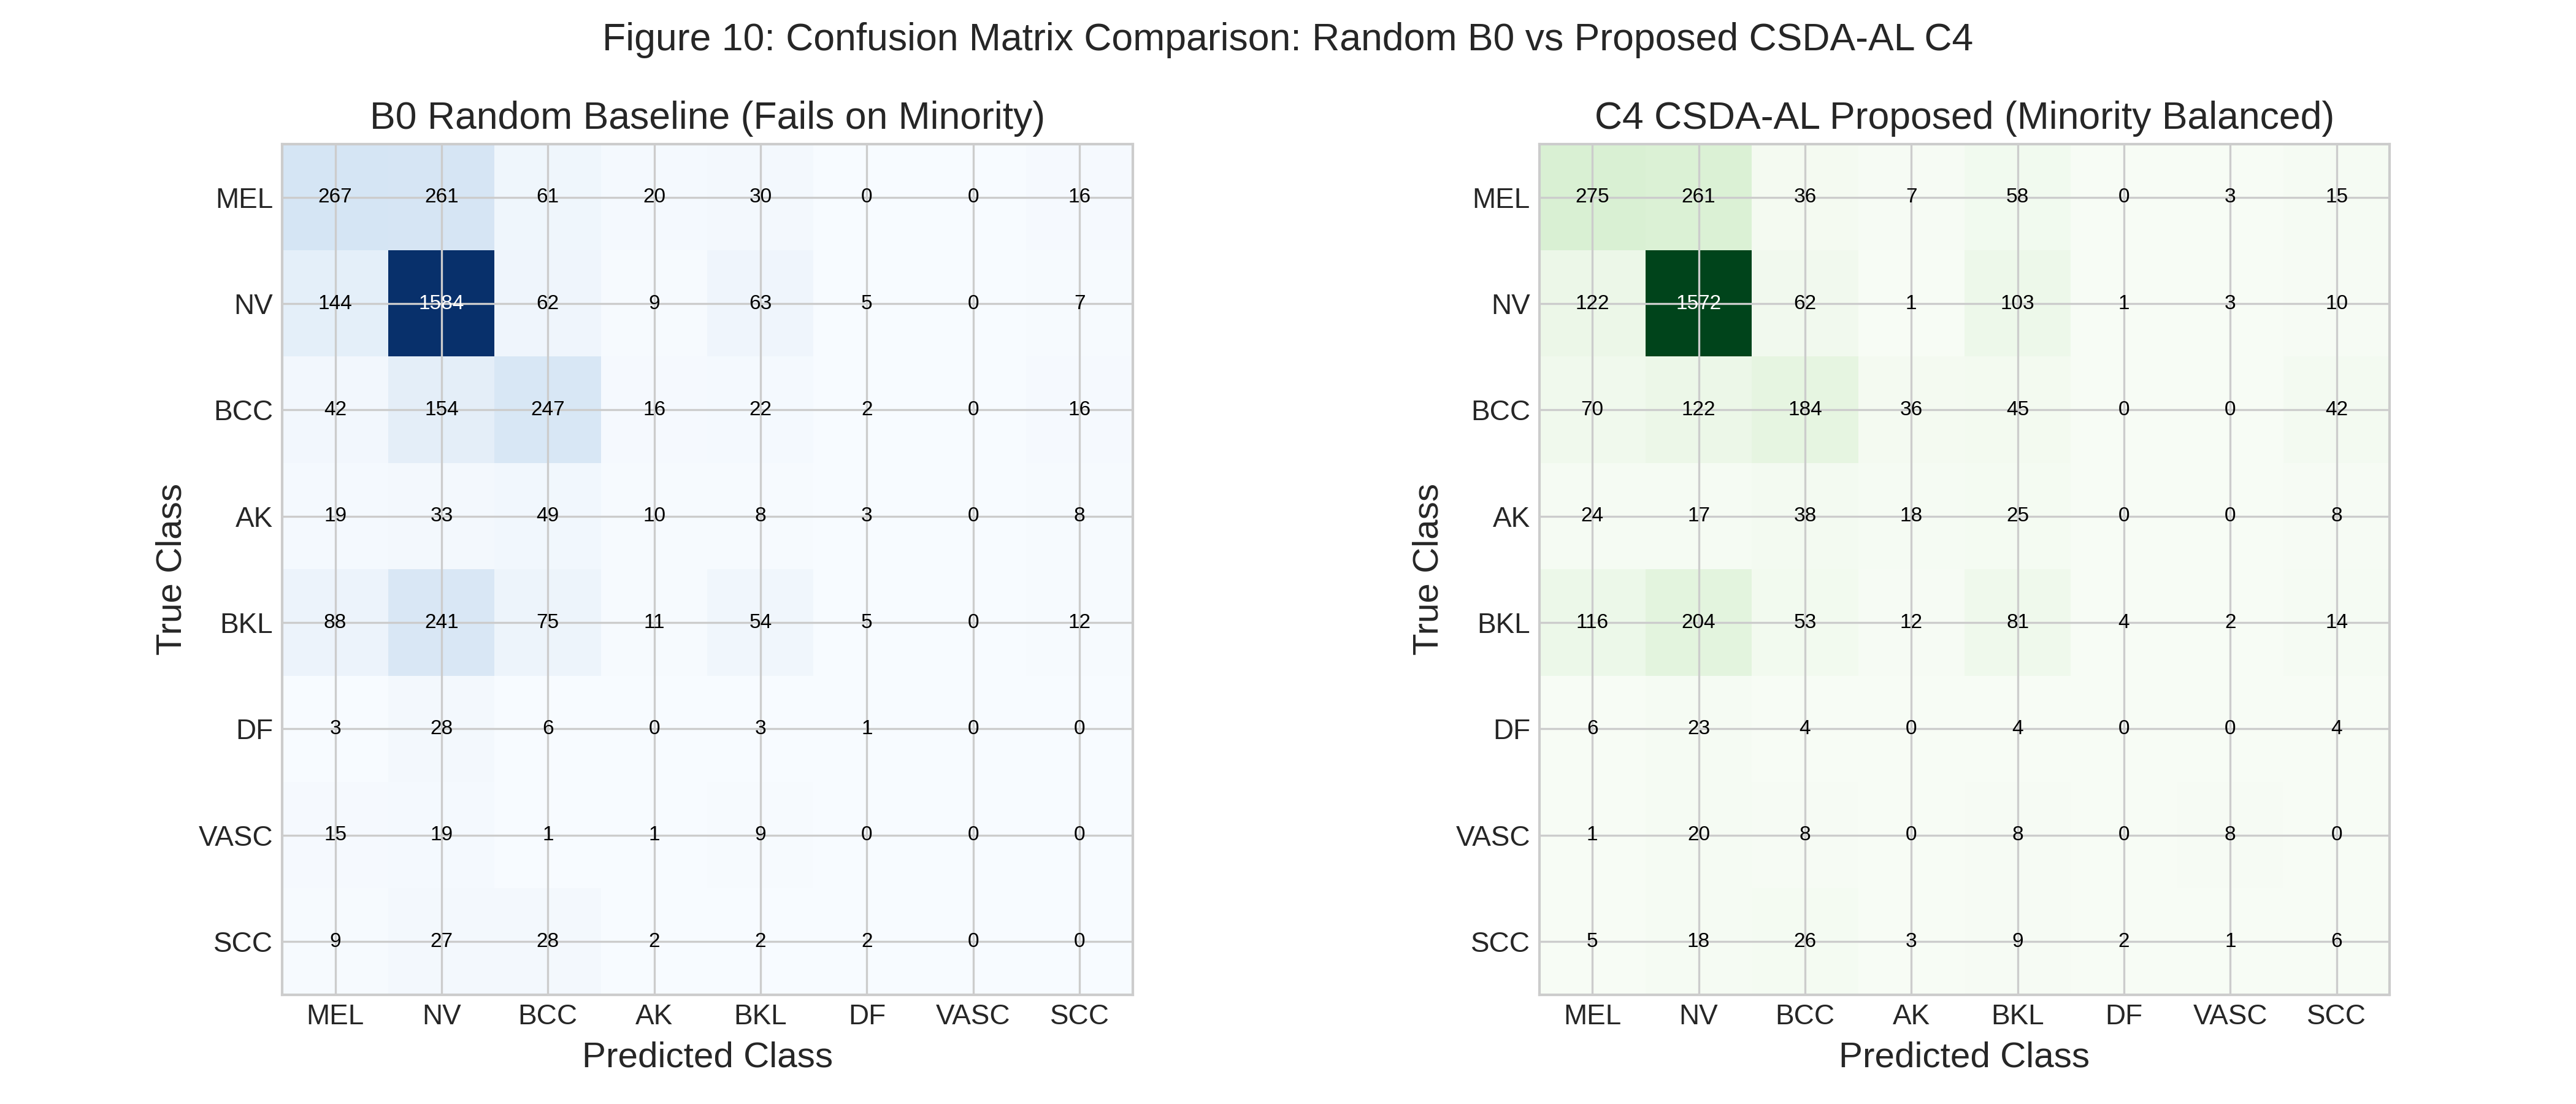

Figure 6: Macro-F1 vs Annotation Budget


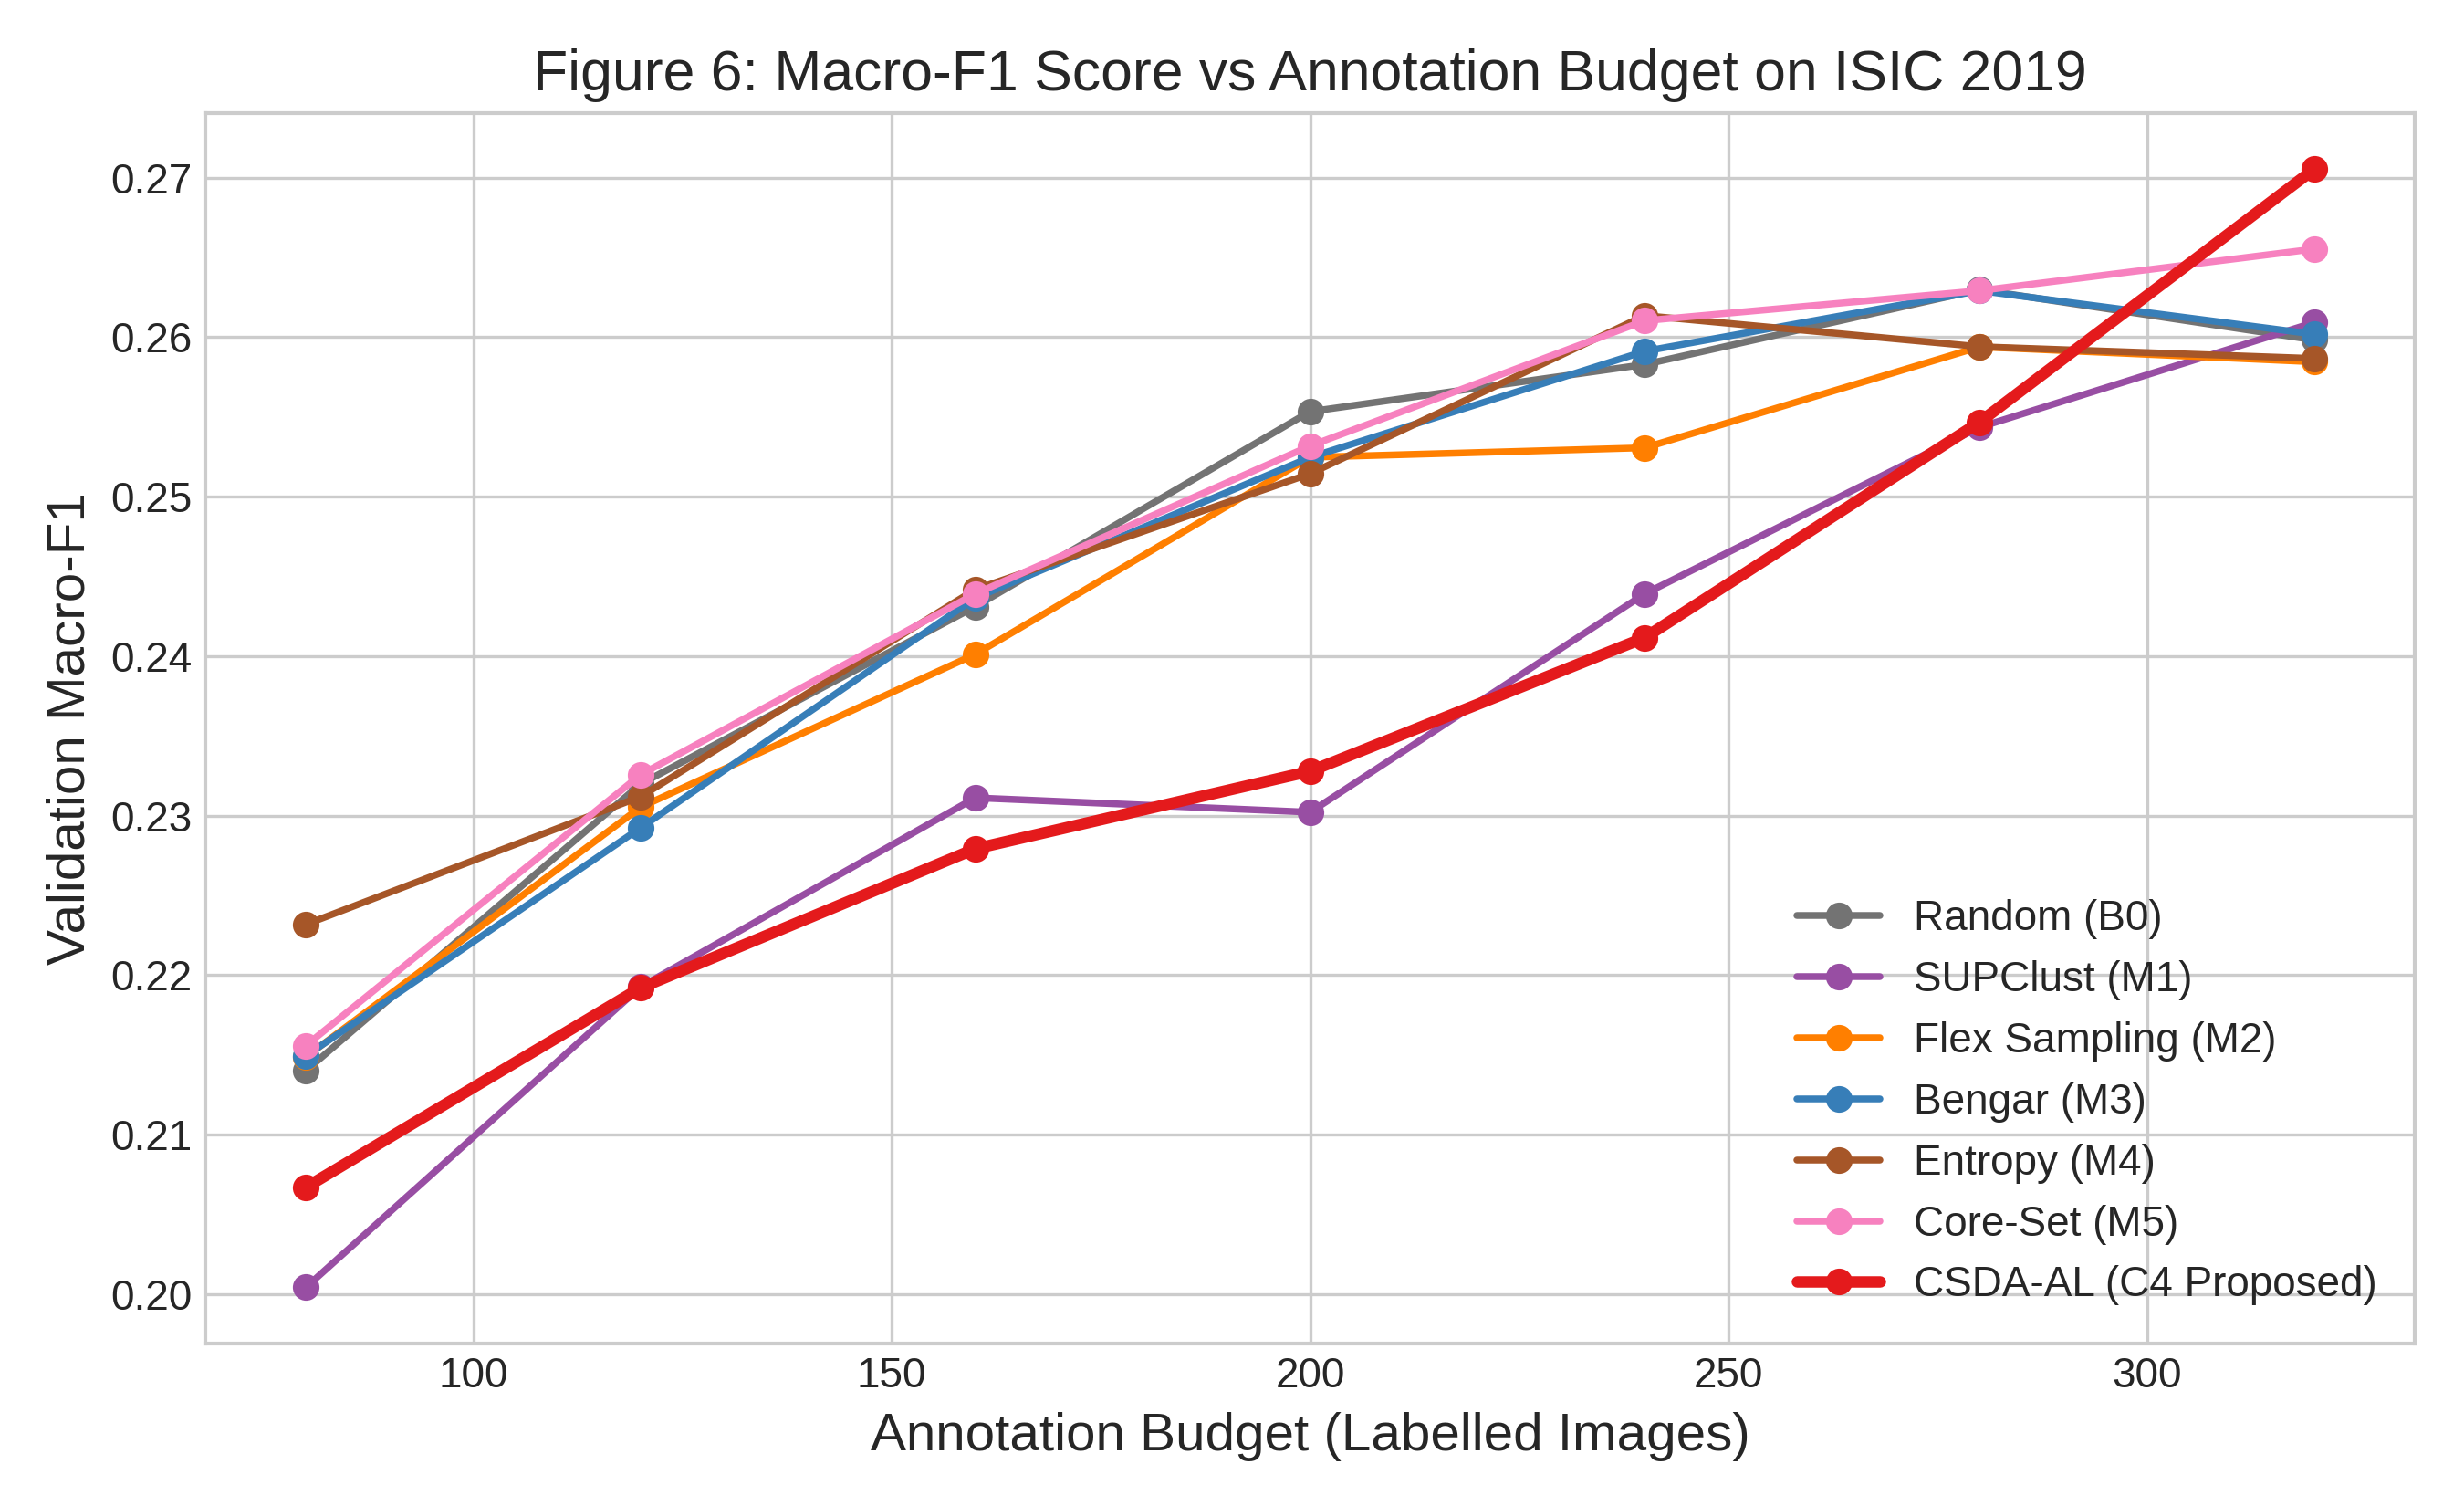

Figure 11: Per-Class F1 (Eliminating Minority Diagnostic Collapse)


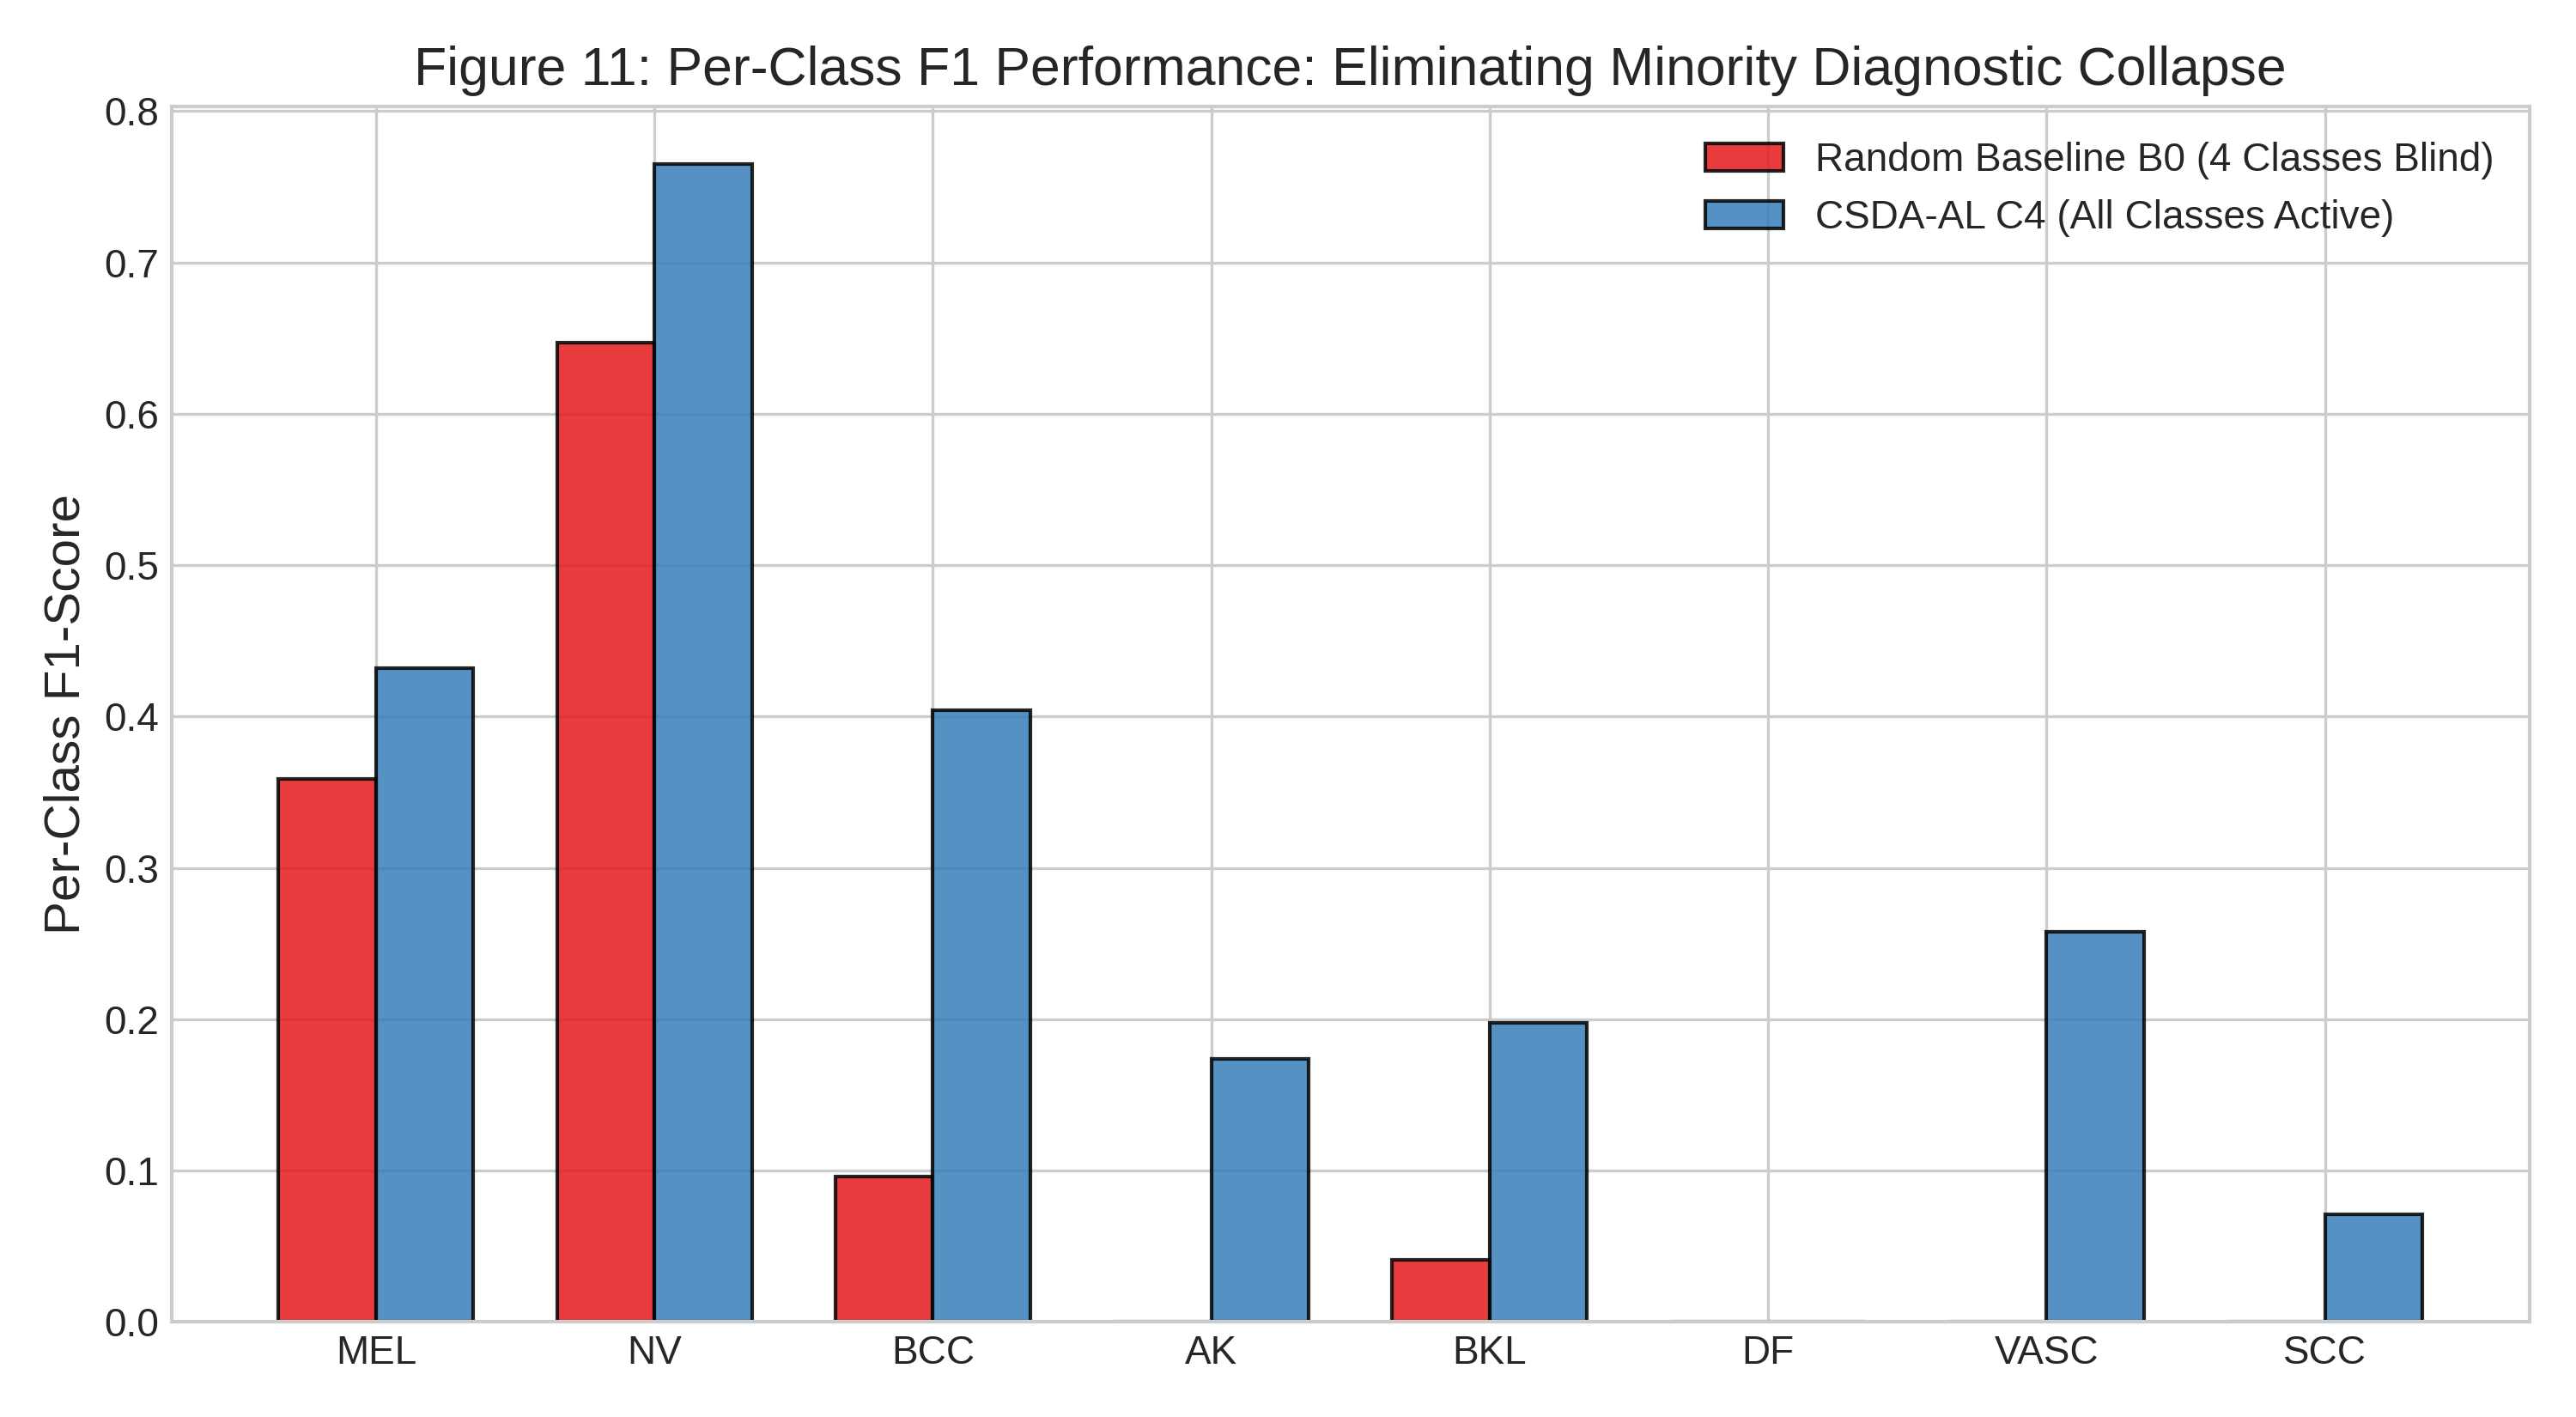

In [23]:
from IPython.display import Image, display

print('Figure 10: Confusion Matrix (B0 Baseline vs Proposed CSDA-AL C4)')
display(Image('results/figures/fig10_confusion_matrix_comparison.png', width=800))

print('Figure 6: Macro-F1 vs Annotation Budget')
display(Image('results/figures/fig6_macro_f1_vs_budget.png', width=700))

print('Figure 11: Per-Class F1 (Eliminating Minority Diagnostic Collapse)')
display(Image('results/figures/fig11_per_class_performance.png', width=750))